In [20]:
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sb

# Exploratory Data Analysis

In [8]:
# load amazon massive dataset

massive_df = pd.read_json('data/1.0/en-US.jsonl', lines=True)
print(massive_df.head())

   id locale partition scenario             intent  \
0   0  en-US      test    alarm          alarm_set   
1   1  en-US     train    alarm          alarm_set   
2   2  en-US     train    alarm          alarm_set   
3   3  en-US      test    audio  audio_volume_mute   
4   4  en-US     train    audio  audio_volume_mute   

                                   utt  \
0      wake me up at five am this week   
1      wake me up at nine am on friday   
2  set an alarm for two hours from now   
3                                quiet   
4                           olly quiet   

                                           annot_utt  worker_id  
0  wake me up at [time : five am] [date : this week]          1  
1  wake me up at [time : nine am] on [date : friday]          1  
2       set an alarm for [time : two hours from now]          1  
3                                              quiet          1  
4                                         olly quiet          1  


In [13]:
# split by partition (train, test, validation)

train_df = massive_df[massive_df['partition'] == 'train'].reset_index(drop=True)
val_df = massive_df[massive_df['partition'] == 'dev'].reset_index(drop=True)
test_df = massive_df[massive_df['partition'] == 'test'].reset_index(drop=True)

print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}\n")
print(f"Data count match: {(len(train_df) == 11514) or (len(val_df) == 2033) or (len(test_df) == 2974)}")

Train: 11514 | Val: 2033 | Test: 2974

Data count match: True


In [15]:
# view examples of utt, intent, annot_utt

print(train_df[['utt', 'intent', 'annot_utt']].head(10))

                                            utt               intent  \
0               wake me up at nine am on friday            alarm_set   
1           set an alarm for two hours from now            alarm_set   
2                                    olly quiet    audio_volume_mute   
3                                          stop    audio_volume_mute   
4                    olly pause for ten seconds    audio_volume_mute   
5                         pause for ten seconds    audio_volume_mute   
6          make the lighting bit more warm here  iot_hue_lightchange   
7  please set the lighting suitable for reading  iot_hue_lightchange   
8                                 time to sleep     iot_hue_lightoff   
9                            time to sleep olly     iot_hue_lightoff   

                                           annot_utt  
0  wake me up at [time : nine am] on [date : friday]  
1       set an alarm for [time : two hours from now]  
2                                         

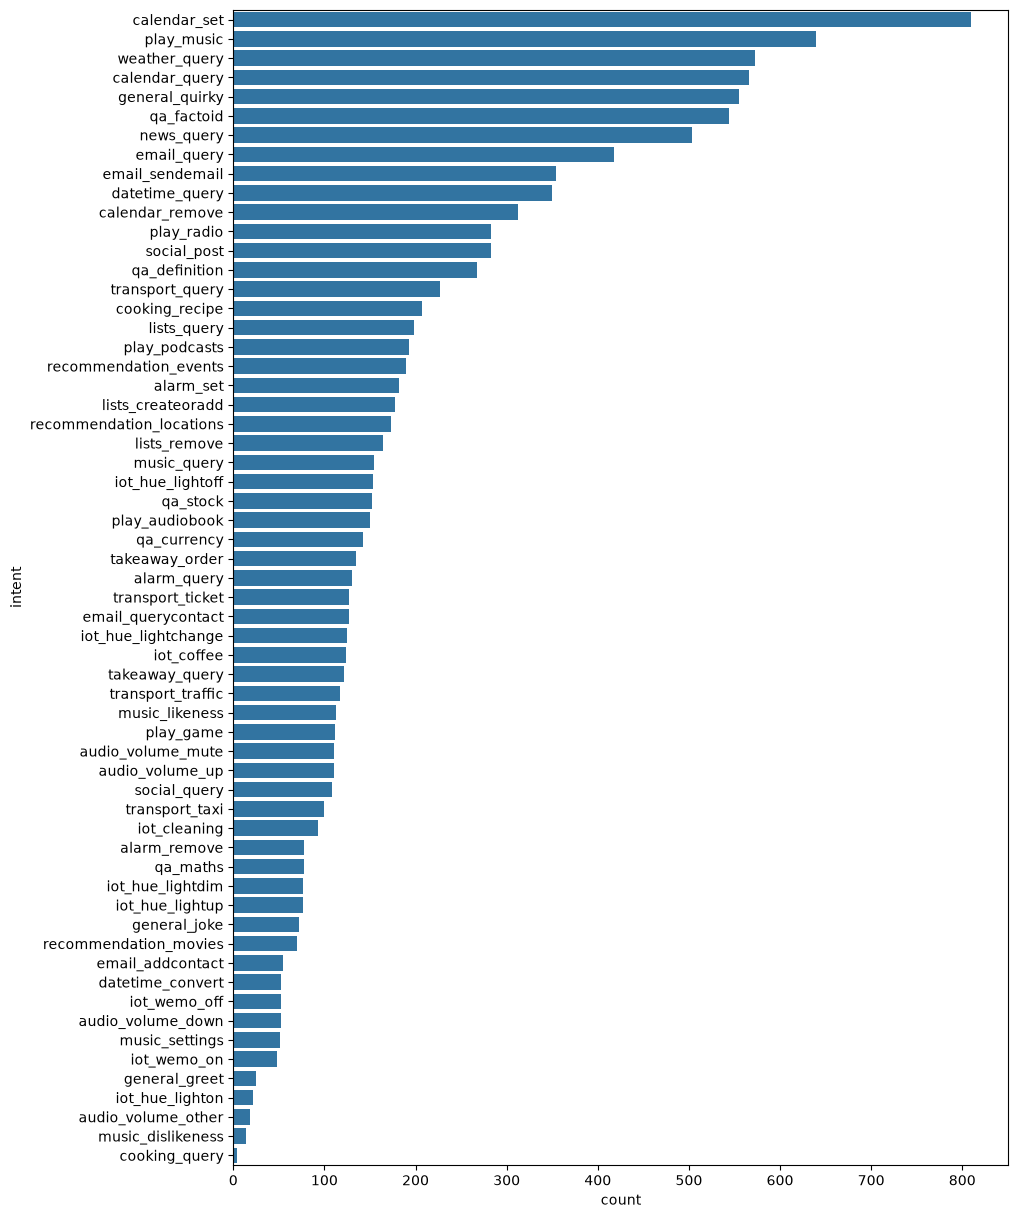

In [24]:
# check intent distribution

plt.figure(figsize=(10, 15)) 
sb.countplot(data=train_df, y='intent', order=train_df['intent'].value_counts().index)
plt.show()

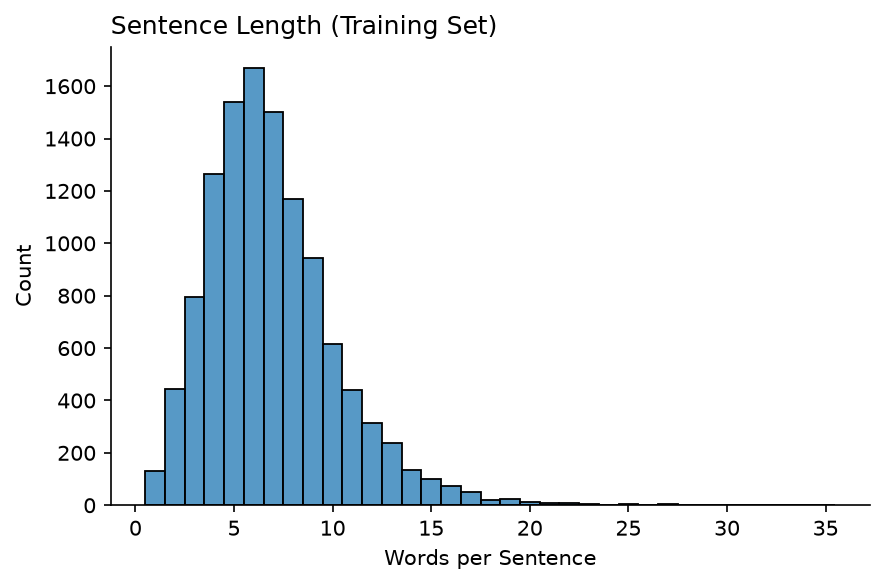

In [26]:
# get token count per entry
train_df['n_tokens'] = train_df['utt'].str.split().str.len()

# sentence length distribution
fig, ax = plt.subplots(figsize=(6, 4), dpi=150)
sb.histplot(data=train_df, x="n_tokens", ax=ax, discrete=True)
ax.set_title("Sentence Length (Training Set)", loc="left")
ax.set_xlabel("Words per Sentence")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

In [34]:
# get all words from train place them in an array
train_words = train_df['utt'].str.split().explode()

# get unique words 
train_vocab_size = train_words.nunique()

print(f"Vocabulary Size: {train_vocab_size}")

Vocabulary Size: 5302


In [35]:
# get words in dev and test set that does not appear in train

# get all words from train place them in an array
train_vocab = set(train_df['utt'].str.split().explode())

# get all words from dev place them in an array
val_vocab = set(val_df['utt'].str.split().explode())

# get all words from test place them in an array
test_vocab = set(test_df['utt'].str.split().explode())

val_unk_words = val_vocab - train_vocab
test_unk_words = test_vocab - train_vocab

print(f"Number of unknown words in validation set: {len(val_unk_words)}")
print(f"Sample of unknown words in validation set: {list(val_unk_words)[:10]}\n")
print(f"Number of unknown words in test set: {len(test_unk_words)}")
print(f"Sample of unknown words in test set: {list(test_unk_words)[:10]}")

Number of unknown words in validation set: 439
Sample of unknown words in validation set: ['marinara', 'adviser', 'required', 'flip', 'aud', 'implement', 'kindly', 'mega', 'excel', 'sexiest']

Number of unknown words in test set: 653
Sample of unknown words in test set: ['daisy', 'reducing', 'succeeding', 'vitaly', 'gallon', 'dos', 'closed', 'jerk', 'motivation', 'mins']


In [42]:
# count entries with no slot

no_slots_mask = ~train_df['annot_utt'].str.contains('\[', na=False)
no_slots_count = no_slots_mask.sum()
no_slots_percentage = (no_slots_count / len(train_df)) * 100

print(f"Sentences with no slots: {no_slots_count}")
print(f"Percentage of total data: {no_slots_percentage:.2f}%")

Sentences with no slots: 3755
Percentage of total data: 32.61%


<>:3: SyntaxWarning: invalid escape sequence '\['
<>:3: SyntaxWarning: invalid escape sequence '\['
/var/folders/w8/d9x92py92j792gw_1kyfc8sh0000gn/T/ipykernel_11866/1044832266.py:3: SyntaxWarning: invalid escape sequence '\['
  no_slots_mask = ~train_df['annot_utt'].str.contains('\[', na=False)


In [40]:
# count slot entries

slot_series = train_df['annot_utt'].str.findall(r'\[([a-zA-Z0-9_\-]+)\s*:')
slot_counts = slot_series.explode().value_counts()

print("----- Slot Type Counts -----")
print(slot_counts)

----- Slot Type Counts -----
annot_utt
date                    1816
place_name              1086
event_name               998
person                   864
time                     797
media_type               477
business_name            383
weather_descriptor       320
transport_type           318
food_type                295
relation                 251
timeofday                239
artist_name              232
device_type              226
definition_word          225
currency_name            217
house_place              198
list_name                191
business_type            189
news_topic               183
music_genre              181
player_setting           160
radio_name               131
song_name                128
order_type               107
color_type               100
game_name                 87
general_frequency         84
personal_info             75
audiobook_name            73
podcast_descriptor        68
meal_type                 63
playlist_name             62
time